# Computer vision libraries in PyTorch:
`torchvision`: PyTorch computer vision bas domain lib
- `torchvision.datasets`: get datasets, data loading functions
- `torchvision models`: get pretrained models
- `torchvision.transforms`: 操作 images

`PyTorch`
- `torch.utils.data.Dataset`: base dataset class
- `torch.utils.data.DataLoader`: 在一dataset上创建一个迭代器

In [167]:
import torchvision
import torch
from torch import nn

import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

print(torch.__version__)
print(torchvision.__version__)

2.12.0+cu126
0.27.0+cu126


## 1. Get data
we use FashionMNIST from `torchvision.datasets`

### 1.1 Download data and check shape and stuff

In [168]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    transform=ToTensor(),
    download=True,
    target_transform=None
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    transform=ToTensor(),
    download=True,
    target_transform=None
)

In [169]:
len(train_data), len(test_data)

(60000, 10000)

In [170]:
train_data

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [171]:
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [172]:
image.shape, label

(torch.Size([1, 28, 28]), 9)

In [173]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [174]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [175]:
class_names[label]

'Ankle boot'

### 1.2 Visualize data

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

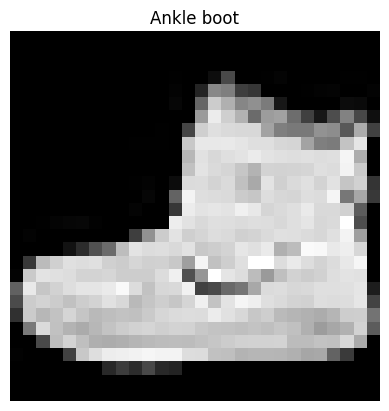

In [176]:
plt.title(class_names[label])
plt.imshow(image.squeeze(), cmap="gray")
plt.axis(False)

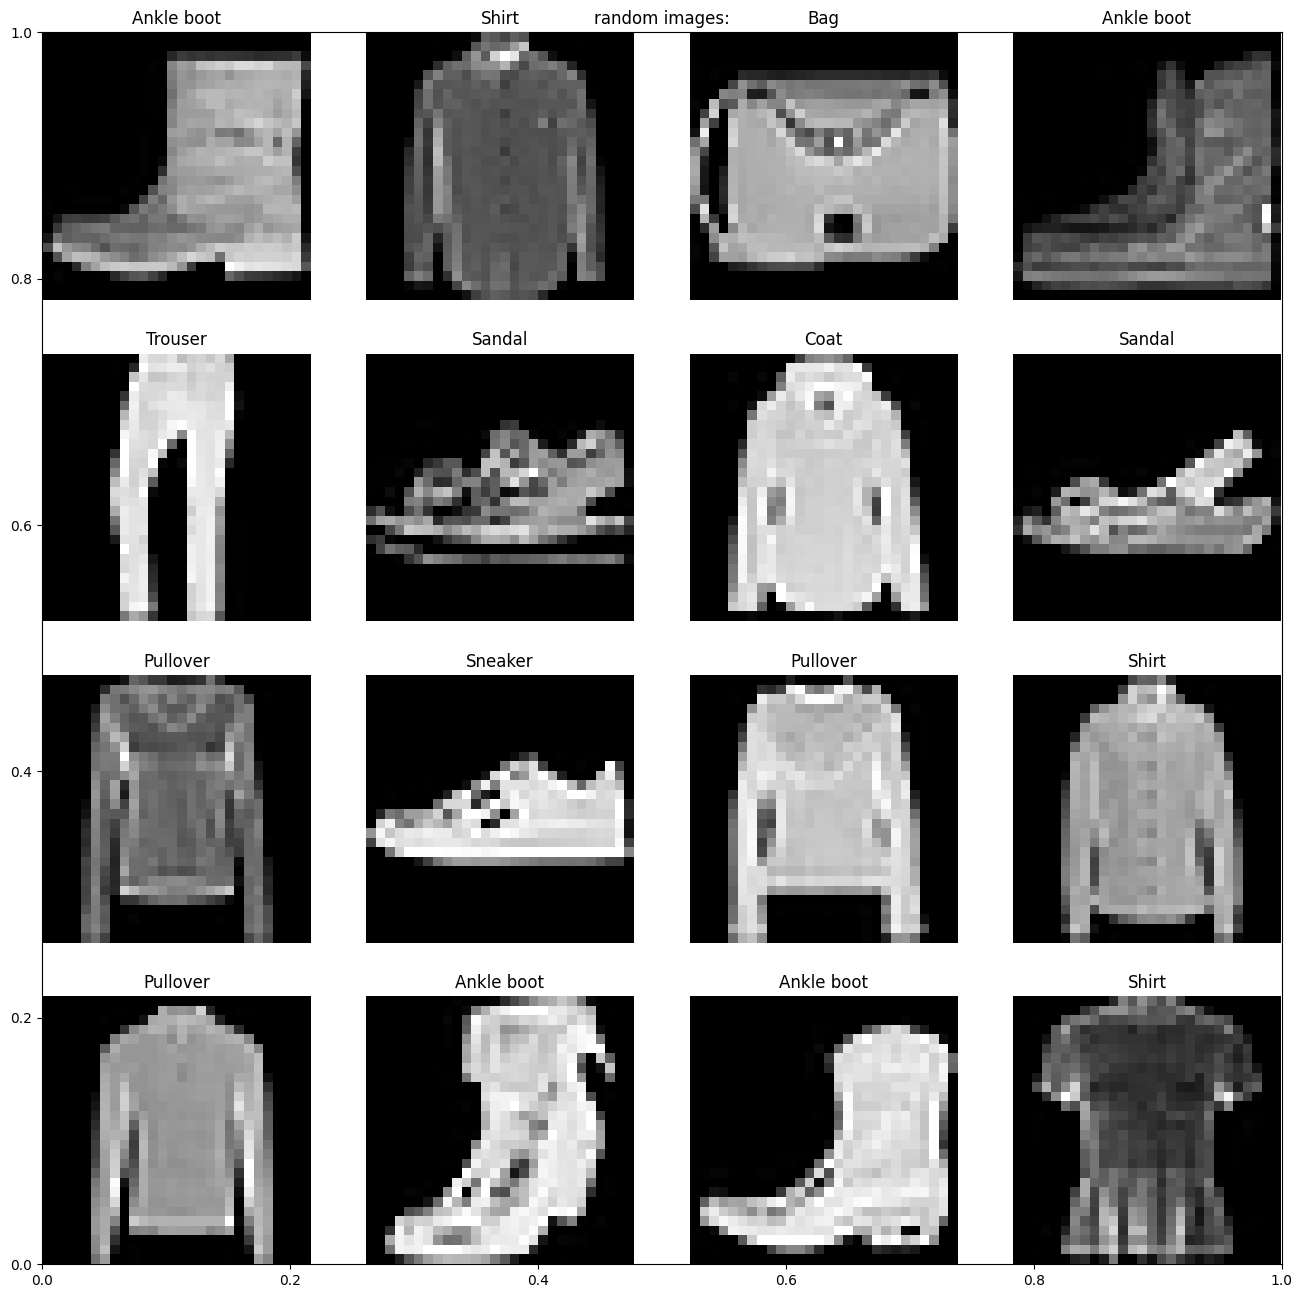

In [177]:
torch.manual_seed(42)

fig = plt.figure(figsize=(16, 16))
plt.title("random images:")

rows, cols = 4, 4
for i in range(1, rows * cols + 1):
    random_index = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_index]
    # print(random_index)
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.axis(False)

### 1.3 Prepare Dataloader

`PyTorch datasets` -> `Dataloader`. Dataloader turns the dataset into PyTorch Iterable, more specificlly, batches

Why batches?
1. 内存没法一次性装所有data, 因此把data按`batch_size`分组, 每次取一组
2. 如果不用batch, 需要遍历完所有data（一个epoch）才能更新. 而有了batch后只需要遍历完batch即可更新一次参数

In [178]:
from torch.utils.data import DataLoader

# setup the batch_size hyper param
BATCH_SIZE = 32

# Datasets->Iterables(Batches)
train_dataloader = DataLoader(dataset=train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(dataset=test_data, batch_size=BATCH_SIZE, shuffle=False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x241bf0a0a10>,
 <torch.utils.data.dataloader.DataLoader at 0x241bf1078c0>)

In [179]:
print(f"Length of train dataloader: {len(train_dataloader)} of batch_size {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} of batch_size {BATCH_SIZE}")


Length of train dataloader: 1875 of batch_size 32
Length of test dataloader: 313 of batch_size 32


In [180]:
# get a batch
# next(): 返回迭代器的下一个值
# iter(): 获取obj的一个迭代器
train_features_batch, train_labels_batch = next(iter(train_dataloader))
# batch_size, color_channels, height, width
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: 8, label size: torch.Size([])


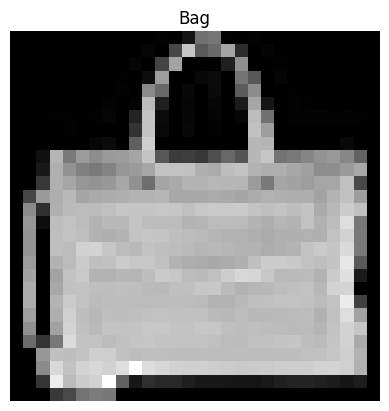

In [181]:
# 从batch中取random image并show
# random number
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()

# get data
image, label = train_features_batch[random_idx], train_labels_batch[random_idx]

# plot
plt.imshow(image.squeeze(), cmap="grey")
plt.title(class_names[label])
plt.axis(False)

print(f"Image size: {image.shape}")
print(f"Label: {label}, label size: {label.shape}")

## 2. Build Model

### 2.1 Flattern

In [182]:
flattern_model = nn.Flatten()
sample_image = train_features_batch[0]
output = flattern_model(sample_image)
print(f"Before: {sample_image.shape}")
print(f"After: {output.shape}")

Before: torch.Size([1, 28, 28])
After: torch.Size([1, 784])


### 2.2 Baseline Model

In [183]:
class FashionMNISTModelV0(nn.Module):
    def __init__(self, input_features, hidden_units, output_features):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_features, out_features= hidden_units),
            nn.Linear(in_features=hidden_units, out_features= output_features)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layer_stack(x)

In [184]:
model_0 = FashionMNISTModelV0(28*28, 10, len(class_names)).to("cpu")

In [185]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[-0.0042, -0.0145,  0.0237,  ..., -0.0319,  0.0206, -0.0111],
                      [-0.0272,  0.0052,  0.0173,  ...,  0.0023,  0.0029,  0.0097],
                      [ 0.0272, -0.0169,  0.0213,  ...,  0.0307, -0.0014, -0.0287],
                      ...,
                      [-0.0101, -0.0093,  0.0068,  ..., -0.0126, -0.0139, -0.0208],
                      [-0.0275,  0.0082,  0.0330,  ...,  0.0330,  0.0033,  0.0030],
                      [-0.0047, -0.0345,  0.0140,  ...,  0.0228,  0.0321, -0.0169]])),
             ('layer_stack.1.bias',
              tensor([ 0.0152, -0.0084,  0.0227, -0.0054, -0.0284, -0.0354, -0.0013,  0.0105,
                      -0.0211,  0.0281])),
             ('layer_stack.2.weight',
              tensor([[ 0.1500,  0.1907,  0.1457, -0.3050, -0.0580,  0.1643,  0.1565, -0.2877,
                       -0.1792,  0.2305],
                      [-0.2618,  0.2397, -0.0610,  0.0232,  0.1542,  0.0851, -0.

In [186]:
dummy_x = torch.rand(size=(1, 1, 28, 28)) # batch_size, color_channels, height, width
model_0(dummy_x)

tensor([[-0.5382, -0.2103, -0.1958, -0.2007,  0.4601, -0.1884,  0.1586,  0.2547,
         -0.3227, -0.3623]], grad_fn=<AddmmBackward0>)

### 2.3 Setup Loss Function and Optimizer

In [187]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

### 2.4 Create a time function

在实验ML的时候, 你想要track:
1. Model performance(loss, acc, etc)
2. How fast the model is

In [188]:
from timeit import default_timer as timer

def print_time(start_time: float, end_time: float, device="None"):
    total = end_time - start_time
    print(f"running time on device {device} is: {total} seconds.")

In [189]:
start_time = timer()
# some code here
end_time = timer()
print_time(start_time, end_time, "cpu")

running time on device cpu is: 1.3899989426136017e-05 seconds.


## 3. Train Baseline Model

### 3.1 Training and Testing loop

注意`optimizer`会在每个`batch`更新一次参数而不是每个`epoch`

In [190]:
len(train_dataloader), len(train_dataloader.dataset)

(1875, 60000)

In [191]:
next(model_0.parameters()).device, str(next(model_0.parameters()).device)

(device(type='cpu'), 'cpu')

In [192]:
from tqdm.auto import tqdm, trange # tqdm: 一个进度条库, tqdm.auto会根据当前python环境(notebook, scripts, ...)自动选择最佳的tqdm样式; trange(x) = tqdm(range(x))
from helper_functions import accuracy_fn

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

# 在experiment阶段设置一个小的epoch
epochs = 3
# 开始时间
start_time = timer()

for epoch in trange(epochs):
    train_loss = 0
    # training
    print(f"Training on Epoch: { epoch }\n===============")
    for batch_idx, (X, y) in enumerate(train_dataloader): # enumerate包裹list, tuple等会额外返回index
        model_0.train()
        # 1. forward pass
        train_logits = model_0(X)
        
        # 2. calculate loss
        loss = loss_fn(train_logits, y)
        train_loss += loss
        
        # 3. zero_grad
        optimizer.zero_grad()
        
        # 4. loss backpropagation
        loss.backward()
        
        # 5. step
        optimizer.step()
        
        if batch_idx % 400 ==0:
            # len(X): 一个batch中有几条数据
            # len(train_dataloader.dataset) 数据总数
            print(f"Batch: {batch_idx/BATCH_SIZE}, Data progress: {batch_idx * len(X)} / {len(train_dataloader.dataset)}")
    # 计算patch平均train_loss
    # len(train_dataloader)为batch数
    train_loss /= len(train_dataloader)
    
    # testing
    test_loss, test_acc =0, 0
    model_0.eval()
    with torch.inference_mode():
        for X_test, y_test in test_dataloader:
            # 1. forward pass
            test_logits = model_0(X_test)
            # 2. calculate loss
            test_loss += loss_fn(test_logits, y_test)
            test_acc += accuracy_fn(y_test, test_logits.argmax(dim=1)) # 不用softmax是因为softmax不改变大小关系, 因此可以直接argmax
        
        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)
    
    # print
    print(f"Train loss: {train_loss} | Test loss: {test_loss}, acc: {test_acc}")
    
end_time = timer()

model0_train_time_on_cpu = print_time(start_time, end_time, str(next(model_0.parameters()).device))

  0%|          | 0/3 [00:00<?, ?it/s]

Training on Epoch: 0
Batch: 0.0, Data progress: 0 / 60000
Batch: 12.5, Data progress: 12800 / 60000
Batch: 25.0, Data progress: 25600 / 60000
Batch: 37.5, Data progress: 38400 / 60000
Batch: 50.0, Data progress: 51200 / 60000
Train loss: 0.5935955047607422 | Test loss: 0.5081419348716736, acc: 82.24840255591054
Training on Epoch: 1
Batch: 0.0, Data progress: 0 / 60000
Batch: 12.5, Data progress: 12800 / 60000
Batch: 25.0, Data progress: 25600 / 60000
Batch: 37.5, Data progress: 38400 / 60000
Batch: 50.0, Data progress: 51200 / 60000
Train loss: 0.47597724199295044 | Test loss: 0.48269781470298767, acc: 82.98722044728434
Training on Epoch: 2
Batch: 0.0, Data progress: 0 / 60000
Batch: 12.5, Data progress: 12800 / 60000
Batch: 25.0, Data progress: 25600 / 60000
Batch: 37.5, Data progress: 38400 / 60000
Batch: 50.0, Data progress: 51200 / 60000
Train loss: 0.45452576875686646 | Test loss: 0.47896066308021545, acc: 83.47643769968052
running time on device cpu is: 24.94556190003641 seconds.

### 3.2 Make model_0 Predictions

write a function to do predictions and evaluate

In [193]:
torch.manual_seed(RANDOM_SEED)
def eval_model(model: torch.nn.Module,
               loss_fn: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               acc_fn,
               device: str="cpu"):
    """Returns a dictionary containing the results of model predicting on data_loader."""
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in tqdm(dataloader):
            X, y = X.to(device), y.to(device)
            y_logits = model(X)
            loss += loss_fn(y_logits, y)
            acc += acc_fn(y, y_logits.argmax(dim=1))
        # caculate avg per batch
        loss /= len(dataloader)
        acc /= len(dataloader)
    
    return {
        "model_name": model.__class__.__name__,
        "loss": loss.item(),
        "acc": acc
    }

In [194]:
model_0_result = eval_model(model_0, loss_fn, test_dataloader, accuracy_fn)

  0%|          | 0/313 [00:00<?, ?it/s]

In [195]:
model_0_result

{'model_name': 'FashionMNISTModelV0',
 'loss': 0.47896066308021545,
 'acc': 83.47643769968052}

## 4. Setup device-agnostic code

In [196]:
device = "cuda" if torch.cuda.is_available() else "cpu"

## 5. Build a better model with non-linaerity

### 5.1 Build a ModelV1 on GPU

In [197]:
class FashionMNISTModelV1(nn.Module):
    def __init__(self, input_features, hidden_units, output_features):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features)
        )
    
    def forward(self, x:torch.Tensor) -> torch.Tensor:
        return self.layer_stack(x)

model_1 = FashionMNISTModelV1(input_features=28*28, hidden_units=10, output_features=len(class_names)).to(device)

In [198]:
next(model_1.parameters()).device

device(type='cuda', index=0)

In [199]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

### 5.2 Functionize train and test loop

In [200]:
def train_step(model: torch.nn.Module,
          dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: nn.Module,
          acc_fn=accuracy_fn,
          device: str=device):
    model.train()
    train_loss, train_acc = 0, 0
    for X, y in dataloader: # enumerate包裹list, tuple等会额外返回index
        X, y = X.to(device), y.to(device)
        
        train_logits = model(X)
        
        loss = loss_fn(train_logits, y)
        train_loss += loss
        train_acc += acc_fn(y, train_logits.argmax(dim=1))
        
        optimizer.zero_grad()
        
        loss.backward()
        optimizer.step()
        
    train_loss /= len(dataloader)
    train_acc /= len(dataloader)
    
    print(f"Train loss: {train_loss:.5f}, Train Acc: {train_acc:.2f}%")

In [201]:
def test_step(model: torch.nn.Module,
          dataloader: torch.utils.data.DataLoader,
          loss_fn: nn.Module,
          acc_fn=accuracy_fn,
          device: str=device):
    test_loss, test_acc =0, 0
    model.eval()
    with torch.inference_mode():
        for X_test, y_test in dataloader:
            X_test, y_test = X_test.to(device), y_test.to(device)
            # 1. forward pass
            test_logits = model(X_test)
            # 2. calculate loss
            test_loss += loss_fn(test_logits, y_test)
            test_acc += acc_fn(y_test, test_logits.argmax(dim=1)) # 不用softmax是因为softmax不改变大小关系, 因此可以直接argmax
        
        test_loss /= len(dataloader)
        test_acc /= len(dataloader)
    
    # print
    print(f"Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

### 5.3 Use the functioon created above to train and test model_1

In [202]:
torch.manual_seed(RANDOM_SEED)
epochs = 3

start_time = timer()

for epoch in tqdm(range(epochs), desc="model_1 training and testing loop"):
    print(f"Epoch {epoch}\n===========================")
    train_step(model_1, train_dataloader, optimizer, loss_fn)
    test_step(model_1, test_dataloader, loss_fn)
end_time = timer()
model1_train_time_on_cpu = print_time(start_time, end_time, device)

model_1 training and testing loop:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 0
Train loss: 0.62518, Train Acc: 77.49%
Test loss: 0.58734, Test acc: 79.44%

Epoch 1
Train loss: 0.46817, Train Acc: 83.29%
Test loss: 0.46961, Test acc: 83.09%

Epoch 2
Train loss: 0.43819, Train Acc: 84.35%
Test loss: 0.45408, Test acc: 83.71%

running time on device cuda is: 21.16344209999079 seconds.


In [203]:
model_1_result = eval_model(model_1, loss_fn, test_dataloader, accuracy_fn, device)

  0%|          | 0/313 [00:00<?, ?it/s]

In [204]:
model_0_result, model_1_result

({'model_name': 'FashionMNISTModelV0',
  'loss': 0.47896066308021545,
  'acc': 83.47643769968052},
 {'model_name': 'FashionMNISTModelV1',
  'loss': 0.45408448576927185,
  'acc': 83.70607028753993})

## 6. Build a Convolutional Neural Network(CNN)
CNN are also known as ConvNets

In [205]:
# 使用的CNN archetecture: Tiny VGG
class FashionMNISTModelV2(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*7*7, out_features=output_shape),
        )
    def forward(self, x):
        x = self.conv_block_1(x)
        # 这些print()用于查看最后一层Linear层的in_features应该为多少(最后一个print)
        # print(f"Output shape of conv_block_1: {x.shape}")
        x = self.conv_block_2(x) 
        # print(f"Output shape of conv_block_2: {x.shape}")
        x = self.classifier(x)
        # print(f"Output shape of classifier: {x.shape}")
        return x

In [206]:
image.shape

torch.Size([1, 28, 28])

In [207]:
# input_shape为color_channels
model_2 = FashionMNISTModelV2(1, 10, len(class_names)).to(device)

In [208]:
dummy_image = torch.randn(size=(1, 1, 28, 28)).to(device)
model_2.eval()
with torch.inference_mode():
    output = model_2(dummy_image)
    print(f"output: \n{output}\noutput shape: {output.shape}")


output: 
tensor([[-1.0237e-04, -6.5327e-04, -7.0773e-03,  4.9903e-02,  1.2112e-01,
          4.2032e-02, -7.0080e-02,  4.2303e-02, -3.0947e-04,  5.1526e-02]],
       device='cuda:0')
output shape: torch.Size([1, 10])


## 7. Train CNN Model

### 7.1 set loss_fn and optimizer

In [209]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_2.parameters(), lr=0.1)

### 7.2 Training and Testing loop

In [210]:
torch.manual_seed(RANDOM_SEED)
epochs = 3

start = timer()

for epoch in trange(epochs):
    print(f"epoch: {epoch}\n--------------")
    train_step(model_2, train_dataloader, optimizer, loss_fn)
    test_step(model_2, test_dataloader, loss_fn)

end = timer()
model2_train_time_on_cpu = print_time(start, end, device)

  0%|          | 0/3 [00:00<?, ?it/s]

epoch: 0
--------------
Train loss: 0.64873, Train Acc: 76.39%
Test loss: 0.41638, Test acc: 85.17%

epoch: 1
--------------
Train loss: 0.36108, Train Acc: 87.11%
Test loss: 0.34631, Test acc: 87.58%

epoch: 2
--------------
Train loss: 0.32251, Train Acc: 88.42%
Test loss: 0.32857, Test acc: 87.98%

running time on device cuda is: 22.027300900022965 seconds.


In [211]:
model_2_result = eval_model(model_2, loss_fn, test_dataloader, accuracy_fn, device)

  0%|          | 0/313 [00:00<?, ?it/s]

In [212]:
model_0_result, model_2_result

({'model_name': 'FashionMNISTModelV0',
  'loss': 0.47896066308021545,
  'acc': 83.47643769968052},
 {'model_name': 'FashionMNISTModelV2',
  'loss': 0.3285742402076721,
  'acc': 87.97923322683707})

### 7.3 Compare results

In [213]:
import pandas as pd
compare_results = pd.DataFrame([model_0_result, model_1_result, model_2_result])
compare_results

,model_name,loss,acc
0,FashionMNISTModelV0,0.478961,83.476438
1,FashionMNISTModelV1,0.454084,83.706070
2,FashionMNISTModelV2,0.328574,87.979233


Text(0, 0.5, 'model')

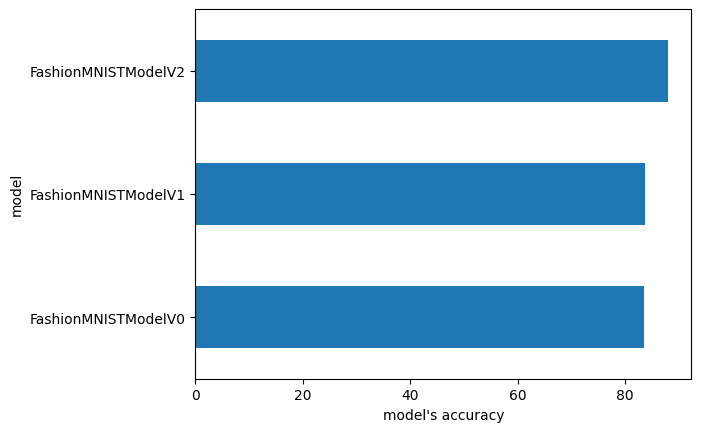

In [214]:
# plot acc
# set_index('model_name'): 把model_name作为行索引(y轴)
# ['acc']: 取出acc这一列
# .plot(): pandas内置绘图函数, 默认以index为y轴
compare_results.set_index('model_name')['acc'].plot(kind='barh')
plt.xlabel('model\'s accuracy')
plt.ylabel('model')

## 8. Make and evaluate random predictions with the best model

### 8.1 Get random samples and predict and plot

In [215]:
def make_predictions(model: nn.Module, data: list, device: 'str') -> torch.Tensor:
    model = model.to(device)
    model.eval()
    pred_probs = []
    with torch.inference_mode():
        for sample in data:
            sample = sample.to(device)
            pred_logit = model(sample.unsqueeze(dim=0))
            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)
            pred_probs.append(pred_prob.cpu())
    return torch.stack(pred_probs)

In [216]:
import random
# random.seed(RANDOM_SEED)

# create sample list
test_samples = []
test_labels = []

for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)
  
# View the first sample shape
test_samples[0].shape

torch.Size([1, 28, 28])

Text(0.5, 1.0, 'Coat')

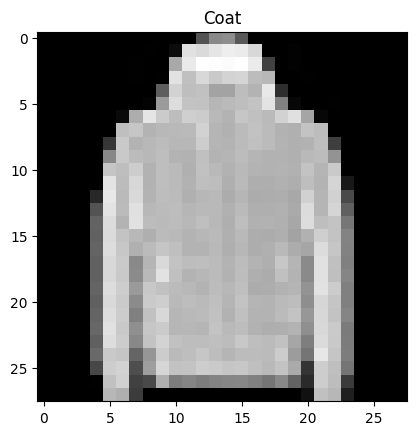

In [217]:
plt.imshow(test_samples[0].squeeze(), cmap="gray")
plt.title(class_names[test_labels[0]])

In [218]:
pred_probs = make_predictions(model_2, test_samples, device)
pred_probs.shape, pred_probs

(torch.Size([9, 10]),
 tensor([[3.7216e-04, 1.2029e-04, 4.0427e-02, 3.2409e-04, 9.5268e-01, 1.2916e-06,
          2.6383e-03, 3.8286e-06, 3.4232e-03, 1.0254e-05],
         [2.1142e-03, 3.2334e-05, 4.7257e-03, 1.0062e-03, 7.5702e-02, 1.8146e-06,
          9.1439e-01, 2.6591e-06, 2.0220e-03, 4.2934e-06],
         [2.1144e-03, 2.5535e-04, 3.1552e-05, 9.9147e-01, 8.6216e-04, 3.3025e-05,
          3.2233e-03, 8.7077e-05, 1.5712e-03, 3.4886e-04],
         [3.4132e-02, 2.5722e-03, 6.5425e-01, 4.1101e-03, 8.1705e-02, 4.5125e-05,
          2.1499e-01, 4.5217e-05, 7.9160e-03, 2.4124e-04],
         [6.0395e-02, 4.4076e-04, 6.2653e-01, 2.1581e-03, 8.6510e-02, 1.1783e-05,
          2.0964e-01, 1.4692e-05, 1.4255e-02, 4.1065e-05],
         [9.7103e-01, 3.9571e-05, 5.3203e-03, 2.9716e-04, 6.2169e-05, 4.1950e-06,
          2.3064e-02, 1.3829e-06, 1.8398e-04, 3.3206e-07],
         [1.3441e-04, 9.9714e-01, 1.1634e-06, 2.4923e-03, 2.0411e-04, 6.3667e-06,
          1.2353e-05, 1.1366e-06, 8.0336e-06, 1.75

In [219]:
pred_labels = pred_probs.argmax(dim=1)
pred_labels

tensor([4, 6, 3, 2, 2, 0, 1, 1, 5])

In [220]:
test_labels

[4, 6, 3, 2, 2, 0, 1, 1, 5]

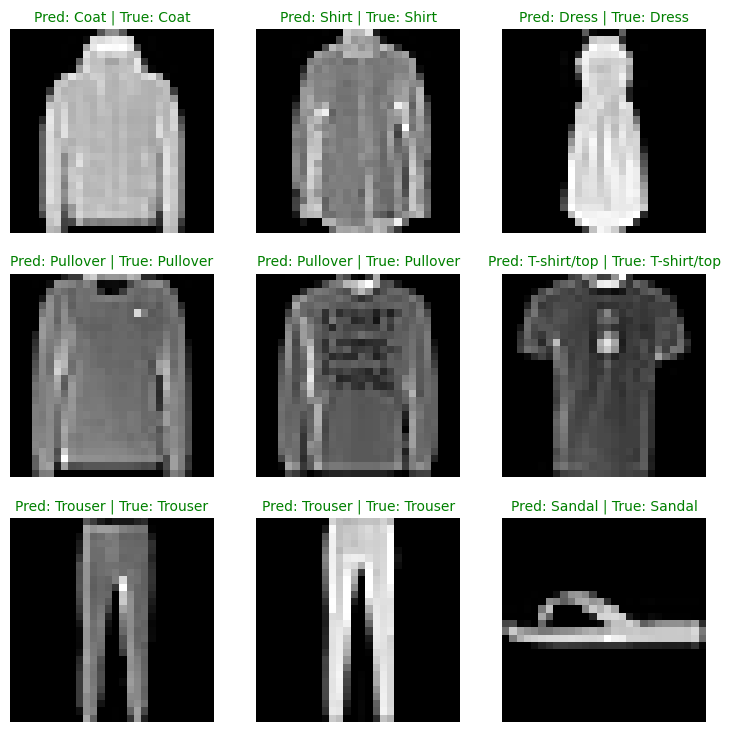

In [221]:
plt.figure(figsize=(9, 9))
rows, cols = 3, 3
for i, sample in enumerate(test_samples):
    plt.subplot(rows, cols, i+1)
    plt.imshow(sample.squeeze(), cmap='gray')
    
    # get label name
    pred_name = class_names[pred_labels[i]]
    true_name = class_names[test_labels[i]]
    
    # set title
    title_text = f"Pred: {pred_name} | True: {true_name}"
    
    # set color based on correctness
    if pred_name == true_name:
        plt.title(title_text, fontsize=10, c='g')
    else:
        plt.title(title_text, fontsize=10, c='r')
    plt.axis(False)

### 8.3 Get confusion matrix

1. 获取整个测试集上的预测结果

In [222]:
# predict 整个test_data
y_preds = []
model_2.eval()
with torch.inference_mode():
    for X, y in tqdm(test_dataloader, desc="Testing whole dataset"):
        X, y = X.to(device), y.to(device)
        y_logit = model_2(X)
        y_pred = torch.softmax(y_logit.squeeze(), dim=0).argmax(dim=1)
        y_preds.append(y_pred.cpu())
# y_preds的每个元素是一个大小为BATCH_SIZE的tensor, shape为 (?, BATCH_SIZE)
# 我希望获得的是一个一维的tensor保存所有预测结果, 因此用cat拼接所有这些tensor成一个tensor
y_pred_tensor = torch.cat(y_preds)

Testing whole dataset:   0%|          | 0/313 [00:00<?, ?it/s]

In [223]:
y_pred_tensor[:10]

tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])

2. 导入torchmetrics用于计算confusion matrix并导入mlxtend用于绘制

In [224]:
import mlxtend
import torchmetrics

In [225]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

confmat = ConfusionMatrix(task="multiclass", num_classes=len(class_names))
confmat_tensor = confmat(preds=y_pred_tensor, 
                         target=test_data.targets)
confmat_tensor

tensor([[692,   9,  41,  65,   6,   1, 178,   0,   8,   0],
        [ 14, 860,   6,  91,  20,   0,   8,   0,   1,   0],
        [ 11,   3, 751,  17, 110,   0, 101,   0,   7,   0],
        [ 30,  14,  30, 848,  48,   0,  23,   0,   6,   1],
        [  8,   5,  86,  45, 724,   0, 125,   0,   7,   0],
        [  4,   1,   4,  10,   1, 763,   8,  93,  87,  29],
        [ 99,   3, 102,  53,  79,   0, 656,   0,   8,   0],
        [  0,   1,   0,   1,   0,  26,   0, 927,   6,  39],
        [ 12,   2,  19,  10,   4,   5,  39,   7, 902,   0],
        [  0,   0,   2,   1,   0,  16,   4, 101,   9, 867]])

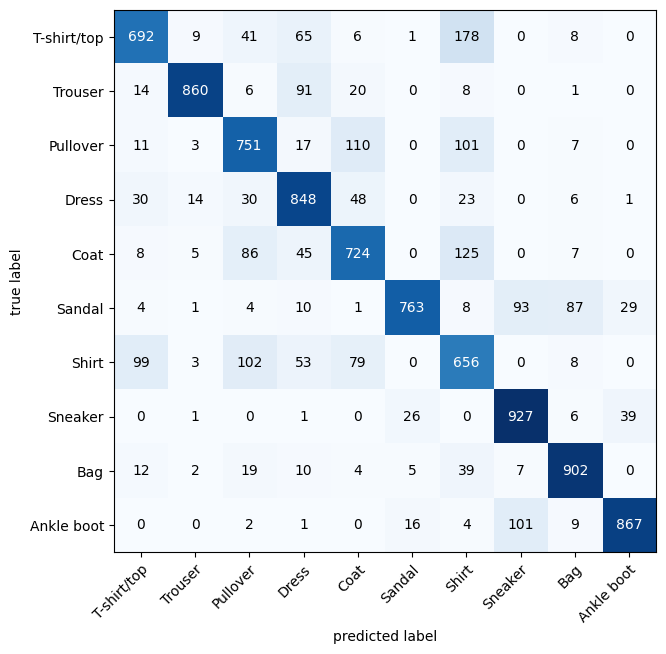

In [226]:
fig, ax = plot_confusion_matrix(
    confmat_tensor.numpy(), # 使用matplotlib, 需要numpy格式
    figsize=(7, 10),
    class_names=class_names
)

## 9. Save and Load the best model

In [227]:
from pathlib import Path

def save_model(model: nn.Module, model_dir: str, model_name: str) -> None:
    MODEL_DIR = Path(model_dir)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_PATH = MODEL_DIR / model_name
    torch.save(obj=model.state_dict(), f=MODEL_PATH)

In [228]:
save_model(model_2, "models", "video_CNN_model.pt")

In [229]:
# load model
model_2_loaded = FashionMNISTModelV2(input_shape=1, hidden_units=10, output_shape=len(class_names)).to(device)
model_2_loaded.load_state_dict(torch.load(f="models/video_CNN_model.pt"))

<All keys matched successfully>

In [230]:
torch.manual_seed(RANDOM_SEED)
model_2_loaded_result = eval_model(model_2_loaded, loss_fn, test_dataloader, accuracy_fn, device)
model_2_loaded_result, model_2_result

  0%|          | 0/313 [00:00<?, ?it/s]

({'model_name': 'FashionMNISTModelV2',
  'loss': 0.3285742402076721,
  'acc': 87.97923322683707},
 {'model_name': 'FashionMNISTModelV2',
  'loss': 0.3285742402076721,
  'acc': 87.97923322683707})

In [231]:
torch.isclose(torch.tensor(model_2_loaded_result["loss"]),
              torch.tensor(model_2_result["loss"]),
              atol=1e-3)

tensor(True)